# Bank Customer Segmentation (1M+ Transactions) |      Сегментация клиентов по поведению и профилю

# **О проекте**
Учебный проект по анализу транзакционного поведения клиентов банка и их сегментации.

**Цель проекта:** исследовать различия в поведении клиентов и сделать сегментацию на основе транзакционной активности,остатков на счетах и персональных данных клиентов.

Результаты исследования могут использоваться для формирования продуктовых гипотез, персонализации предложений и планирования маркетинговых кампаний.


## **Об этом наборе данных**:
## **Источник** - [Bank Customer Segmentation  |  Kaggle](https://www.kaggle.com/datasets/shivamb/bank-customer-segmentation?utm_source=chatgpt.com)


Датасет содержит более чем 1 млн. транзакций и информацию о более чем 800 тыс. клиентах банка Индии
## **Основные признаки**

*   Клиент: идентификатор, дата рождения, пол, местоположение.
*   Счёт: баланс на момент транзакции.
* Транзакция: идентификатор, дата, время и сумма транзакции.

Перед сегментацией необходимо проверить качество данных: пропуски, аномальные значения и противоречия в информации о клиентах и транзакциях.

##**Бизнес-задачи**

1. **Исследовать поведение клиентов**

* Проанализировать количество, частоту и суммы транзакций.

* Изучить распределение остатков на счетах.

* Выявить различия в транзакционной активности клиентов.

2. **Выделить клиентские сегменты**

* Сгруппировать клиентов по доступным поведенческим и финансовым характеристикам.

* Определить размер каждого сегмента и его отличительные особенности.

* Составить понятный профиль каждой группы.

3. **Найти возможности для продуктовых решений**

* Определить сегменты, для которых могут быть актуальны разные банковские предложения.

* Сформулировать гипотезы по повышению активности клиентов и развитию банковских продуктов.

* Предложить способы проверки этих гипотез.


##**Ожидаемый результат**

Клиентские сегментации с описанием их особенностей, визуализация основных закономерностей и продуктовые гипотезы, основанные на результатах анализа данных.

##**Статус проекта**

В работе. Выполняются исследовательский анализ данных (EDA), проверка их качества и подготовка к сегментации.





# Этап очистки

In [ ]:
import pandas as pd
import numpy as np
url = "https://drive.google.com/uc?export=download&id=1EbLNirdYqF52UIFptq-bw-KmsXmFKAlb"
df = pd.read_csv(url,low_memory=False)
df_clean=df.copy()
print('Кол-во строк, столбцов: ',*df_clean.shape)
print('Названия столбцов'.center(80,'='),*df_clean.columns.tolist(),sep='\n')
df_clean.head()

Кол-во строк, столбцов:  1048567 9
===============================Названия столбцов================================
TransactionID
CustomerID
CustomerDOB
CustGender
CustLocation
CustAccountBalance
TransactionDate
TransactionTime
TransactionAmount (INR)


,TransactionID,CustomerID,CustomerDOB,CustGender,CustLocation,CustAccountBalance,TransactionDate,TransactionTime,TransactionAmount (INR)
0,T1,C5841053,10/1/94,F,JAMSHEDPUR,17819.05,2/8/16,143207,25.0
1,T2,C2142763,4/4/57,M,JHAJJAR,2270.69,2/8/16,141858,27999.0
2,T3,C4417068,26/11/96,F,MUMBAI,17874.44,2/8/16,142712,459.0
3,T4,C5342380,14/9/73,F,MUMBAI,866503.21,2/8/16,142714,2060.0
4,T5,C9031234,24/3/88,F,NAVI MUMBAI,6714.43,2/8/16,181156,1762.5



#Первичный анализ датасета
|№|Пизнак| Всего |Уникальных |Пропуски | Описание |Текущий Тип|
|---|---|---|---|---|---|---|
|0|TransactionID|1 048 567|1 048 567|0|ID транзакции|object|
|1|CustomerID|1 048 567|884 265|0|ID Пользователя|object|
|2|CustomerDOB|1 045 170|17 254|3397|Дата рождения|object|
|3|CustGender|1 047 467|3|1 100|Пол|object|
|4|CustLocation|1 048 416|9 355|151|Местоположение|object|
|5|CustAccountBalance|1 046 198|161 328|2369|Баланс счета|float64|
|6|TransactionDate|1 048 567|55|0|Дата сделки|object|
|7|TransactionTime|1 048 567|81 918|0|Транзакционное время|int64|
|8|TransactionAmount (INR)|1 048 567|93 024|0|Сумма транзакции В INR|float64|



*  Полных дубликатов строк 0
*  Уникальных клиентов 884 265






            















In [ ]:
df_clean.info()
print('Кол-во пропусков в столбцах'.center(80,'='),df_clean.isna().sum(),'='*80,sep='\n')
print('Полные дубликаты строк =',df_clean.duplicated().sum())
print('Уникальные значения'.center(80,'='),df_clean.nunique(),sep='\n')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048567 entries, 0 to 1048566
Data columns (total 9 columns):
 #   Column                   Non-Null Count    Dtype  
---  ------                   --------------    -----  
 0   TransactionID            1048567 non-null  object 
 1   CustomerID               1048567 non-null  object 
 2   CustomerDOB              1045170 non-null  object 
 3   CustGender               1047467 non-null  object 
 4   CustLocation             1048416 non-null  object 
 5   CustAccountBalance       1046198 non-null  float64
 6   TransactionDate          1048567 non-null  object 
 7   TransactionTime          1048567 non-null  int64  
 8   TransactionAmount (INR)  1048567 non-null  float64
dtypes: float64(2), int64(1), object(6)
memory usage: 72.0+ MB
==========================Кол-во пропусков в столбцах===========================
TransactionID                 0
CustomerID                    0
CustomerDOB                3397
CustGender                 1100


# **Итоговые решения в CustGender:**


*  Аномалия **CustGender ='T'**;1 строка - заменено на **NaN**.
*  Замечено аномальное CustomerDOB = 1/1/1800




In [ ]:
print('Уникальные значения пола c пропусками: ',df_clean['CustGender'].unique(),'\n','='*80)
print('Количество строк где пол=T:',(df_clean['CustGender']=='T').sum(),'\n','='*80)
display(df_clean[df_clean['CustGender']=='T'])
display(df_clean['CustGender'].value_counts(dropna=False))
print('='*80,'Заменим на nan аномальное значение "T"','='*80,sep='\n')
df_clean.loc[df['CustGender']=='T','CustGender']=np.nan
display(df_clean.iloc[[959987]])
display(df_clean[df_clean['CustomerDOB']=='1/1/1800'])

Уникальные значения пола c пропусками:  ['F' 'M' nan 'T'] 
Количество строк где пол=T: 1 


,TransactionID,CustomerID,CustomerDOB,CustGender,CustLocation,CustAccountBalance,TransactionDate,TransactionTime,TransactionAmount (INR)
959987,T959988,C3380368,1/1/1800,T,CHENNAI,50050.0,10/9/16,170731,32500.0


,count
CustGender,
M,765530
F,281936
NaN,1100
T,1


Заменим на nan аномальное значение "T"


,TransactionID,CustomerID,CustomerDOB,CustGender,CustLocation,CustAccountBalance,TransactionDate,TransactionTime,TransactionAmount (INR)
959987,T959988,C3380368,1/1/1800,NaN,CHENNAI,50050.0,10/9/16,170731,32500.0


,TransactionID,CustomerID,CustomerDOB,CustGender,CustLocation,CustAccountBalance,TransactionDate,TransactionTime,TransactionAmount (INR)
16,T17,C1376215,1/1/1800,M,MUMBAI,77495.15,1/8/16,124727,1423.11
22,T23,C7018081,1/1/1800,M,WAYS PANCHKUVA AHMEDABAD,143.07,3/8/16,104718,110.00
28,T29,C7935438,1/1/1800,M,MOHALI,969436.12,3/8/16,183634,36.90
35,T36,C1211387,1/1/1800,M,AHMEDABAD,11791.25,3/8/16,125915,1075.00
151,T152,C3334638,1/1/1800,M,PUNE,700.00,9/8/16,24912,1500.00
...,...,...,...,...,...,...,...,...,...
1048443,T1048444,C7261226,1/1/1800,M,BHILAI,1393.33,18/9/16,102427,200.00
1048452,T1048453,C3813481,1/1/1800,M,NEW DELHI,984605.24,18/9/16,84644,219.00
1048531,T1048532,C6937679,1/1/1800,M,NEW DELHI,50698.90,18/9/16,184319,598.86
1048533,T1048534,C7431884,1/1/1800,M,MANDIR DHANBAD,53771.64,18/9/16,184049,520.00


# Посмотрим уникальные значение в CustomerDOB
## CustomerDOB имеет тип object, следовательно интерпритируется как строковое значение


*   **CustomerDOB** - копировали в **CustomerDOB_dt**
*   **CustomerDOB_dt** - преобразовали тип в **datatime**



In [ ]:
print('Тип данных CustomerDOB:',df_clean['CustomerDOB'].dtype)
print('='*80,'\nКоличество nan:',df_clean['CustomerDOB'].isna().sum())
print('='*80,'\nКоличество уникальных значений:',df_clean['CustomerDOB'].nunique(),'\n'+'='*80)
display(df_clean['CustomerDOB'].value_counts(dropna=False))

df_clean['CustomerDOB_dt']=pd.to_datetime(df['CustomerDOB'],format='mixed',dayfirst=True,errors='coerce')

print('Тип данных CustomerDOB_dt',df_clean['CustomerDOB_dt'].dtype)
display(df_clean['CustomerDOB_dt'].value_counts(dropna=False))

Тип данных CustomerDOB: object
Количество nan: 3397
Количество уникальных значений: 17254 


,count
CustomerDOB,
1/1/1800,57339
NaN,3397
1/1/89,809
1/1/90,784
6/8/91,699
...,...
14/11/99,1
5/8/41,1
1/6/45,1


Тип данных CustomerDOB_dt datetime64[ns]


,count
CustomerDOB_dt,
1800-01-01,57339
NaT,3397
1989-01-01,809
1990-01-01,784
1991-08-06,699
...,...
1999-11-14,1
2041-08-05,1
2045-06-01,1


# Зафиксируем аномалии после преобразования типа CustomerDOB, видно что преобразование произошло некорректно, например:
## строка с индексом 249422: 27/5/64 -> 27-05-2064

In [ ]:
display(df_clean[['CustomerDOB','CustomerDOB_dt']].sample(25))


,CustomerDOB,CustomerDOB_dt
351668,8/12/88,1988-12-08
669000,6/8/66,2066-08-06
471629,23/6/68,2068-06-23
306844,21/2/89,1989-02-21
693991,1/1/1800,1800-01-01
898805,6/8/88,1988-08-06
758523,5/1/83,1983-01-05
956681,5/1/82,1982-01-05
521006,26/9/86,1986-09-26
521604,1/1/1800,1800-01-01


# **Итоговые решения в CustomerDOB_dt и TransactionDate**:



* **CustomerDOB** - копировали в **CustomerDOB_dt**
*   **CustomerDOB_dt** - преобразовали тип в **datatime**
*   **1-1-1800; количество 57339** - значение интерпретировано как техническая заглушка, **заменено на NaT**
*   **CustomerDOB_dt** - исправили некорректные значения с **"будущей датой рождения"**
* **TransactionDate** - копировали в **TransactionDate_dt**
* **TransactionDate_dt** - преобразовали в **DateTime**
* **TransactionDate_dt** - убрали аномалии д**ата_рождения>даты_транзакции**
* Замечена аномалия на один CustomerID приходится несколько CustomerDOB_dt, а также различаются другие данные.


In [ ]:
#Количество аномалий и пустых значений
print('Количество NaN в CustomerDOB_dt:',df_clean['CustomerDOB_dt'].isna().sum())
print('Количество "1800-01-01" в CustomerDOB_dt:',(df_clean['CustomerDOB_dt']=='1800-01-01').sum())


Количество NaN в CustomerDOB_dt: 3397
Количество "1800-01-01" в CustomerDOB_dt: 57339


In [ ]:
#заменяем NaN и '1800-01-01' на NaT
df_clean.loc[(df_clean['CustomerDOB_dt']=='1800-01-01')|(df_clean['CustomerDOB_dt']=='NaN'),'CustomerDOB_dt']=pd.NaT
print('Количество NaT в CustomerDOB_dt:',(df_clean['CustomerDOB_dt']=='NaT').sum())

Количество NaT в CustomerDOB_dt: 0


In [ ]:
#Преобразуем дату транзакции также в DateTime и проверим отстутвие пропусков и аномалий
df_clean['TransactionDate'].value_counts(dropna=False)
print('Количество пустых значений в TransactionDate:',df_clean['TransactionDate'].isna().sum())
df_clean['TransactionDate_dt']=pd.to_datetime(df_clean['TransactionDate'],format='mixed',dayfirst=True,errors='coerce')
display(df_clean['TransactionDate_dt'].value_counts())


Количество пустых значений в TransactionDate: 0


,count
TransactionDate_dt,
2016-08-07,27261
2016-08-13,26921
2016-08-06,26585
2016-09-04,26564
2016-09-03,26431
2016-09-10,25761
2016-08-14,25596
2016-09-11,25454
2016-08-15,24171


In [ ]:
#Откорректируем дату рождения по транзакции

#некорректные значения по маске
mask=df_clean['CustomerDOB_dt']>df_clean['TransactionDate_dt']
print('Некорректные значения в CustomerDOB_dt:',mask.sum())

#сохраним некорректные значения до исправления
primer=df_clean.loc[mask,['CustomerDOB_dt','TransactionDate_dt']].head(10).copy()
display(primer)

#Исправляем даты
df_clean.loc[mask,'CustomerDOB_dt']=df_clean.loc[mask,'CustomerDOB_dt']-pd.DateOffset(years=100)

primer['CustomerDOB_после']=df_clean.loc[primer.index,'CustomerDOB_dt']
display(primer)
mask_after=df_clean['CustomerDOB_dt']>df_clean['TransactionDate_dt']
print('Некорректных значений после исправления:',mask_after.sum())


Некорректные значения в CustomerDOB_dt: 117578


,CustomerDOB_dt,TransactionDate_dt
1,2057-04-04,2016-08-02
3,2073-09-14,2016-08-02
5,2072-10-08,2016-08-02
15,2068-07-10,2016-08-01
30,2067-01-21,2016-08-03
51,2066-07-25,2016-08-05
61,2075-04-11,2016-08-05
79,2067-05-25,2016-08-01
80,2067-05-04,2016-08-01
87,2074-09-03,2016-08-06


,CustomerDOB_dt,TransactionDate_dt,CustomerDOB_после
1,2057-04-04,2016-08-02,1957-04-04
3,2073-09-14,2016-08-02,1973-09-14
5,2072-10-08,2016-08-02,1972-10-08
15,2068-07-10,2016-08-01,1968-07-10
30,2067-01-21,2016-08-03,1967-01-21
51,2066-07-25,2016-08-05,1966-07-25
61,2075-04-11,2016-08-05,1975-04-11
79,2067-05-25,2016-08-01,1967-05-25
80,2067-05-04,2016-08-01,1967-05-04
87,2074-09-03,2016-08-06,1974-09-03


Некорректных значений после исправления: 0


# Итоговая проверка исправленного датафрейма

In [ ]:
print('Некорректных значений дата_рождения>даты_транзакции после исправления:',mask_after.sum())
print('Даты-заглушки 1800-01-01:',(df_clean['CustomerDOB_dt']=='1800-01-01').sum())
print('Количество пустых значений',df_clean['CustomerDOB_dt'].isna().sum())
print('Количество строк:',len(df_clean))

Некорректных значений дата_рождения>даты_транзакции после исправления: 0
Даты-заглушки 1800-01-01: 0
Количество пустых значений 60736
Количество строк: 1048567


# Расчитаем возраст на момент транзакции

,CustomerDOB_dt,TransactionDate_dt,Age
0,1994-01-10,2016-08-02,22.0
1,1957-04-04,2016-08-02,59.0
2,1996-11-26,2016-08-02,19.0
3,1973-09-14,2016-08-02,42.0
4,1988-03-24,2016-08-02,28.0
...,...,...,...
1048562,1990-04-08,2016-09-18,26.0
1048563,1992-02-20,2016-09-18,24.0
1048564,1989-05-18,2016-09-18,27.0
1048565,1978-08-30,2016-09-18,38.0


=============================Распределение возраста=============================
Младше 10 лет, кол-во транзацкций: 192
Старше 100 лет, кол-во транзакций: 0
Пустые значения, кол-во транзакций: 60736


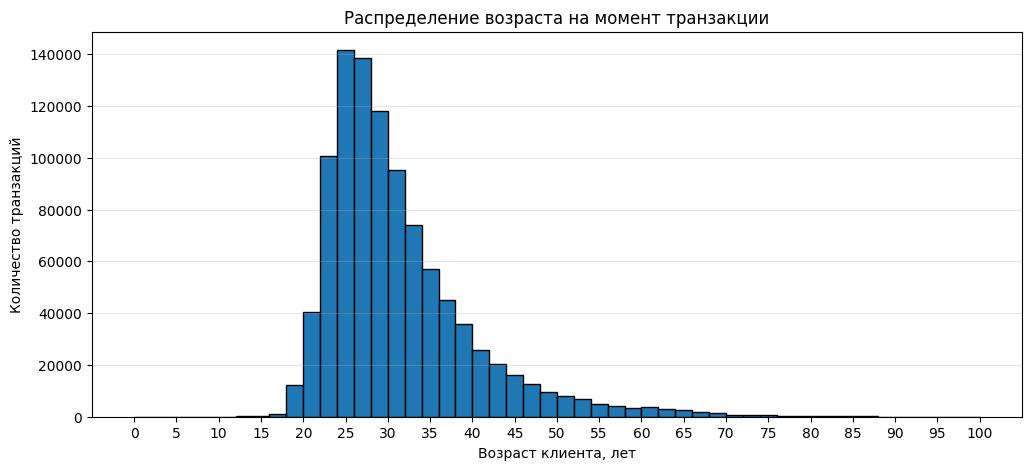

Кол-во транзакций младше 10 лет: 192
Уникальных транзакций младше 10 лет: 192
Количество клиентов с разными датами рождение: 128583


,CustomerDOB_dt
CustomerID,
C1010011,2
C1010012,1
C1010014,2
C1010018,1
C1010024,1
...,...
C9099836,1
C9099877,1
C9099919,1


,TransactionID,CustomerID,CustomerDOB,CustGender,CustLocation,CustAccountBalance,TransactionDate,TransactionTime,TransactionAmount (INR),CustomerDOB_dt,TransactionDate_dt,Age
33670,T33671,C1010011,19/8/92,F,NOIDA,32500.73,26/9/16,123813,4750.0,1992-08-19,2016-09-26,24.0
173508,T173509,C1010011,5/8/83,M,NEW DELHI,120180.54,9/8/16,11229,356.0,1983-08-05,2016-08-09,33.0


In [ ]:
birth=(
      (df_clean['TransactionDate_dt'].dt.month<df_clean['CustomerDOB_dt'].dt.month)
        |
      (
      (df_clean['TransactionDate_dt'].dt.month==df_clean['CustomerDOB_dt'].dt.month)
      &
      (df_clean['TransactionDate_dt'].dt.day<df_clean['CustomerDOB_dt'].dt.day)

    )
)




df_clean['Age']=(df_clean['TransactionDate_dt'].dt.year- df_clean['CustomerDOB_dt'].dt.year)-birth
display(df_clean[['CustomerDOB_dt','TransactionDate_dt','Age']])
print('Распределение возраста'.center(80,'='))


print('Младше 10 лет, кол-во транзацкций:',(df_clean['Age']<10).sum())
print('Старше 100 лет, кол-во транзакций:',(df_clean['Age']>100).sum())
print('Пустые значения, кол-во транзакций:',(df_clean['Age'].isna()).sum())



import matplotlib.pyplot as plt
plt.figure(figsize=(12,5))

plt.hist(

         df_clean['Age'].dropna(),
         bins=range(0,102,2),
         edgecolor='black'
)

plt.title('Распределение возраста на момент транзакции')
plt.xlabel('Возраст клиента, лет')
plt.ylabel('Количество транзакций')
plt.xticks(range(0,101,5))
plt.grid(axis='y', alpha=0.3)

plt.show()

print('Кол-во транзакций младше 10 лет:',(df_clean['Age']<10).sum())
print('Уникальных транзакций младше 10 лет:',df_clean.loc[df_clean['Age']<10, 'CustomerID'].nunique())

#Проверим нет ли у одного клиента нескольких дат рождения
customer_dob_count=df_clean.groupby('CustomerID')['CustomerDOB_dt'].nunique()
print('Количество клиентов с разными датами рождение:', (customer_dob_count>1).sum())
display(customer_dob_count)
display(df_clean.loc[df_clean['CustomerID']=='C1010011'])

# Как мы видим младше 10 лет целых 192 транзакции, по законодательству Индии несовершеннолетнему можно открыть счёт с участием опекуна. Поэтому оставляем данные как есть.

In [ ]:
df_clean['Age'].describe()
#Проверим нет ли у одного клиента нескольких дат рождения
customer_dob_count=df_clean.groupby('CustomerID')['CustomerDOB_dt'].nunique()
print('Количество клиентов с разными датами рождение:', (customer_dob_count>1).sum())
display(customer_dob_count)
display(df_clean.loc[df_clean['CustomerID']=='C1010011'])

Количество клиентов с разными датами рождение: 128583


,CustomerDOB_dt
CustomerID,
C1010011,2
C1010012,1
C1010014,2
C1010018,1
C1010024,1
...,...
C9099836,1
C9099877,1
C9099919,1


,TransactionID,CustomerID,CustomerDOB,CustGender,CustLocation,CustAccountBalance,TransactionDate,TransactionTime,TransactionAmount (INR),CustomerDOB_dt,TransactionDate_dt,Age
33670,T33671,C1010011,19/8/92,F,NOIDA,32500.73,26/9/16,123813,4750.0,1992-08-19,2016-09-26,24.0
173508,T173509,C1010011,5/8/83,M,NEW DELHI,120180.54,9/8/16,11229,356.0,1983-08-05,2016-08-09,33.0


# **Обнаружена проблема у одного ID пользователя, разные даты рождения, пол**. Это **серьезная проблема** нашего датасета и она требует дополнительного исследования.


*   133 184 Клиента имеют рассхождения в поле или дате рождения
*   Новый пункт




In [ ]:
Customer_id_chek=df_clean.groupby('CustomerID').agg(
    transactions=('TransactionID','count'),
    dob_unique=('CustomerDOB_dt','nunique'),
    gender_unique=('CustGender','nunique')

).reset_index()

mask_anomali_gender_dob=(
    (Customer_id_chek['dob_unique']>1)&(Customer_id_chek['gender_unique']>1)

)
mask_anomali_gender_or_dob=(
    (Customer_id_chek['dob_unique']>1)|(Customer_id_chek['gender_unique']>1)

)

print(
    'Разные DOB в исходных данных:',
    (df.groupby('CustomerID')['CustomerDOB'].nunique() > 1).sum()
)

print(
    'Разные DOB после обработки:',
    (df_clean.groupby('CustomerID')['CustomerDOB_dt'].nunique() > 1).sum()
)


print('ID пропусков:',df_clean['CustomerID'].isna().sum())
print('ID без пропусков:',(df_clean['CustomerID'].nunique()) )
print('ID с несколькими транзакциями:', (Customer_id_chek['transactions']>1).sum())
print('ID с разными датами рождения:', (Customer_id_chek['dob_unique']>1).sum())
print('ID с разным полом:', (Customer_id_chek['gender_unique']>1).sum())
print('ID с разным полом и датой рождения одновременно:', mask_anomali_gender_dob.sum())

display(Customer_id_chek.loc[(Customer_id_chek['dob_unique']>1)|(Customer_id_chek['gender_unique']>1),'CustomerID'])

transactions_anomaly=Customer_id_chek.loc[(Customer_id_chek['dob_unique']>1)|(Customer_id_chek['gender_unique']>1),'transactions'].sum()


Разные DOB в исходных данных: 141466
Разные DOB после обработки: 128583
ID пропусков: 0
ID без пропусков: 884265
ID с несколькими транзакциями: 143612
ID с разными датами рождения: 128583
ID с разным полом: 59902
ID с разным полом и датой рождения одновременно: 55301


,CustomerID
0,C1010011
2,C1010014
6,C1010031
7,C1010035
12,C1010041
...,...
884006,C9093042
884047,C9094224
884106,C9095886
884121,C9096252


# **27.37% транзакций** связаны с ID клиентов,у которых обнаружены **противоречивые персональные данные**. Это достаточно существенная часть.
## **Проблема** - мы не можем надежно связать их с одним человеком, что может исказить результаты сегментации. В реальном бизнесе такую проблему считают серьезным нарушением качества клиентских данных, от правильной идентификации клиента зависят не только маркетинговые предложения, но и обслуживание счетов, безопасность и выполнение регулятора.

## В реальном бизнесе:


*   **Определяют источник проблемы**: проверяют, не произошла ли ошибка при выгрузке, объединении баз, обезличивании или назначении идентификаторов. В нашем случае причина неизвестна, и мы не можем её узнать.
*   **Сверяют записи с эталонной базой клиентов**:у банка должна быть клиентская система и подтверждённые идентификационные данные. Проверяют, какая запись соответсвует реальному человеку и какие операции ему принадлежат.
*   **Помечают конфликтующие данные**: пока причина не найдена, такие данные могут исключить из персонализированных расчетов. При этом сами финансовые транзакции остаются в учётных системах.
*   **Исправляют первопричину и контролируют качество**: восстанавливают связи по достоверным источникм, далее вводят проверки, чтобы ошибка не повторялась.

# **Что решено сделать в рамках ПЭТ-проекта**
## Доступа к внутренней базе банка нет, этот датасет всё что есть, поэтому:

*   Для **персонализированной сегментации**, будут использоваться пользователи без противоречий. т.е. **исключить CustomerID с разными CustomerDOB или CustomerGender**
*   Для анализа общего обьема операций и сумм транзакций,**СustomerID с разными CustomerDOB или CustomerGender не исключаем**









In [ ]:
print('Процент пользователей с разными датами рождения или полом, от всех  уникальных пользователей, равен:', f" {mask_anomali_gender_or_dob.sum()/df_clean['CustomerID'].nunique()*100:.2f}% ")
print('Процент транзакций таких пользователей от всего датасета, равен:', f" {transactions_anomaly/df_clean['TransactionID'].count()*100:.2f}% ")


Процент пользователей с разными датами рождения или полом, от всех  уникальных пользователей, равен:  15.06% 
Процент транзакций таких пользователей от всего датасета, равен:  27.37% 
